# Conditional kidney field synthesis

Can one shared emitter reconstruct the three kidney endpoints that independent splats can already represent?
The input is a categorical specimen condition (ShamL, Day2L or Week6L). Shared learned slots and a small network emit
centers, radii, rotations, latent profiles and amplitudes; a frozen shared decoder renders expression.
Emitted splats are **not subsequently fitted** to the requested specimen.

This is an **in-sample capacity experiment**, not held-out prediction or disease progression. Animal and state are
confounded. It uses the completed independent experiment's measured genes, QC, decoder, coordinates and regional losses.
Independent splat parameters are evaluation references, not training targets or initialization.
Each specimen retains its own normalized coordinate frame; no anatomical registration is implied.
Result figures compare independent reconstructions with the completed joint expression-and-occupancy model.
The expression-only emitter is loaded solely to warm-start joint training. An inference-only blending prototype follows the endpoint results. Evaluation uses observed measurement coordinates, and physical sizes are supplied.


In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.collections import PolyCollection
from matplotlib.patches import Patch, Ellipse
from sklearn.metrics import pairwise_distances_argmin
from dotenv import load_dotenv
from IPython.display import display

PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p/'spatsplat').is_dir() and (p/'paper').is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('Launch this notebook from inside the repository')
sys.path.insert(0, str(PROJECT_ROOT))
load_dotenv(PROJECT_ROOT/'.env')
from paper.data_loaders.xenium_kidney_iri import data_directory
from paper.kidney_iri_synthesis import load_reference, run_emitter, compare_endpoints, sha256
from paper.cohort_regional_synthesis import prepare_regions
from paper.conditional_field import export_field
from paper.kidney_iri_reconstruction import export_independent

pd.options.display.float_format = lambda value: f'{value:.4g}'
np.set_printoptions(precision=4, suppress=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE)


Device: cuda


In [2]:
# This is the completed 1.0-sharpness independent pilot, not the earlier 0.25 run.
SOURCE_RUN = 'e29bc647aaa3'
RUN_EMITTER = False
FORCE_EMITTER_RETRAIN = False
ARCHITECTURE = dict(width=128, slot_dim=32, embedding_dim=16)

SOURCE = data_directory()/'processed/xenium_kidney_iri'/SOURCE_RUN
CHECKPOINT_ROOT = PROJECT_ROOT/'notebooks/checkpoints/xenium_kidney_iri'
reference = load_reference(SOURCE, CHECKPOINT_ROOT, DEVICE)
records, ae, genes = reference['records'], reference['ae'], reference['genes']
cfg = reference['manifest']['config'].copy()
ROUNDS = cfg['steps']  # One update per specimen per round: 15,000 updates for this pilot.
regions = prepare_regions(records, cfg['widths_um'], cfg['min_measurements'])
display(pd.DataFrame([dict(condition=r['condition'], sample=r['section'], state=r['state'],
    side=r['kidney_side'], measurements=len(r['xy']), genes=len(genes),
    coordinate_scale_um=r['scale_um']) for r in records]))
display(pd.DataFrame([dict(splats_per_field=cfg['num_splats'], kernel_sharpness=cfg['kernel_sharpness'],
    updates_per_specimen=ROUNDS, total_updates=ROUNDS*len(records), **ARCHITECTURE)]))


,condition,sample,state,side,measurements,genes,coordinate_scale_um
0,0,ShamL,Sham,L,106423,299,4901
1,1,Day2L,Day2,L,115165,299,5929
2,2,Week6L,Week6,L,148693,299,5381


,splats_per_field,kernel_sharpness,updates_per_specimen,total_updates,width,slot_dim,embedding_dim
0,1024,1,5000,15000,128,32,16


## Matched settings and cached training

The emitter uses the source run's 1,024 splats per field, sharpness 1.0, physical radius bounds and
50/100/200 um regional objective. Every sampled region includes all its measurements, not just its center.
Geometry and molecular outputs are trainable; the decoder stays frozen. Initial slots use pooled observed regional
profiles, never independently fitted splat parameters. The shared network makes this a different optimization problem
from fitting three separate fields, even with matched update counts.

Set `RUN_EMITTER=True` for the first fit. A completed matching checkpoint is reused even with that flag enabled;
`FORCE_EMITTER_RETRAIN=True` forces a fresh fit only when training is enabled. Incomplete checkpoints are retained
for inspection but restarted, not resumed. No autoencoder or independent field is retrained here.


In [3]:
code_paths = [PROJECT_ROOT/p for p in ['paper/kidney_iri_synthesis.py', 'paper/kidney_iri_reconstruction.py',
    'paper/conditional_field.py', 'paper/cohort_regional_synthesis.py',
    'paper/zhuang_regional_fidelity.py', 'spatsplat/models.py', 'spatsplat/autoencoder.py']]
provenance = dict(source_run=SOURCE_RUN, config=cfg, architecture=ARCHITECTURE, rounds=ROUNDS,
    source_hashes={str(p.relative_to(p.parents[0]))+':'+str(i): sha256(p)
                   for i, p in enumerate(reference['paths'])},
    code={str(p.relative_to(PROJECT_ROOT)): sha256(p) for p in code_paths}, torch_version=str(torch.__version__))
RUN_ID = hashlib.sha256(json.dumps(provenance, sort_keys=True).encode()).hexdigest()[:12]
OUTPUT = data_directory()/'processed/kidney_iri_synthesis'/RUN_ID
FIGURES = PROJECT_ROOT/'figures/kidney_iri_synthesis'/RUN_ID
CHECKPOINT = PROJECT_ROOT/'notebooks/checkpoints/kidney_iri_synthesis'/RUN_ID/'emitter.pt'
print('Emitter run:', RUN_ID)
print('Checkpoint:', CHECKPOINT)
emitter, history = run_emitter(records, regions, ae, cfg, ARCHITECTURE, CHECKPOINT, provenance,
    DEVICE, rounds=ROUNDS, log_every=cfg['log_every'], train=RUN_EMITTER, force=FORCE_EMITTER_RETRAIN)
if emitter is not None:
    OUTPUT.mkdir(parents=True, exist_ok=True)
    (OUTPUT/'manifest.json').write_text(json.dumps(provenance, indent=2))
    history.to_csv(OUTPUT/'training_history.csv', index=False)
else:
    print('Remaining model-dependent sections will skip until training is explicitly enabled.')


Emitter run: 951b885921a2
Checkpoint: /home/javeda/Documents/Research/spatsplat/notebooks/checkpoints/kidney_iri_synthesis/951b885921a2/emitter.pt
Loaded completed emitter; no training.


## Joint tissue occupancy

Warm-start the completed emitter above and jointly fine-tune expression plus a separate emitted occupancy field.
Both branches share specimen embeddings. The saved expression-only emitter is unchanged; no AE or independent field
is retrained. Occupancy is a probability, with a fixed 0.5 threshold used only for binary display/export.

Supervision is a **coordinate-derived support proxy**, not histological ground truth: near-measurement canvas points
are positive, sufficiently distant border-connected exterior points are negative, and gaps/boundary uncertainty remain
unlabeled. Inspect these masks before training. Canvas blocks monitor proxy agreement, not unseen specimens. The full reference support anchors center placement,
including monitoring blocks, so these scores are not independent held-out occupancy validation.

Expression training and regional metrics remain **ungated**. A fixed reference distance map now pulls centers into positive tissue support, replacing the old 150 um allowance.
The center penalty is mean squared distance divided by 50 um squared, weighted by 0.1 after a 200-round ramp.
Unknown regions remain excluded from occupancy BCE, but are not preferred center locations.
Predicted occupancy is not used to pull centers, so the mask cannot expand to accommodate misplaced splats.
Occupancy does not guarantee that every expression splat lies inside tissue. Physical size is still supplied metadata.


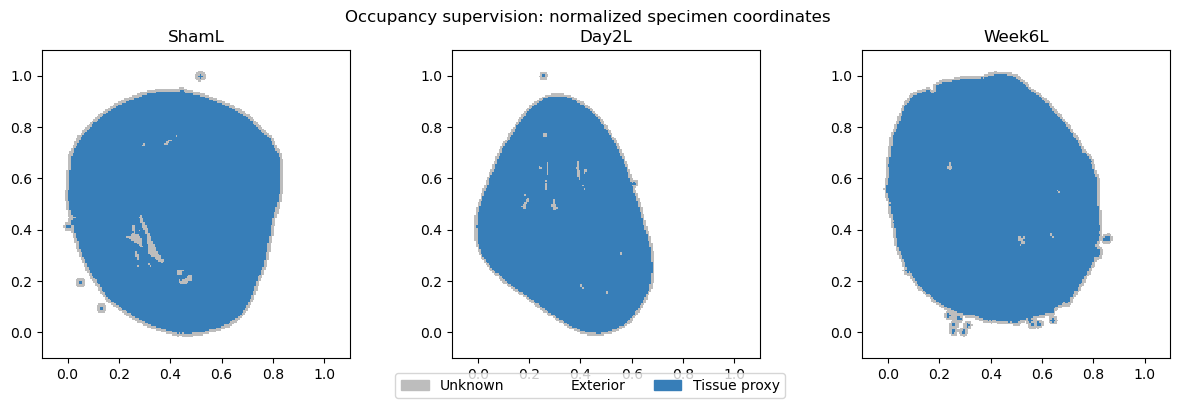

,sample,positive_fraction,unknown_fraction,exterior_fraction
0,ShamL,0.417,0.03315,0.5499
1,Day2L,0.3054,0.02081,0.6738
2,Week6L,0.4371,0.02965,0.5333


In [4]:
from paper.kidney_iri_occupancy import prepare_support, run_joint, geometry_support_summary
from paper.cohort_occupancy import predict_occupancy, occupancy_metrics
from paper.conditional_field import predict_field

RUN_OCCUPANCY = True
FORCE_OCCUPANCY_RETRAIN = False
OCC_CFG = dict(seed=3107, rounds=2000, log_every=100, lr=1e-4,
    canvas_size=192, padding=.1, positive_radius_um=40., negative_radius_um=100., block_pixels=8,
    occupancy_side=16, width=128, occupancy_batch_size=2048, occupancy_weight=.1, threshold=.5,
    center_support_weight=.1, center_distance_scale_um=50., center_warmup_rounds=200)
occ_grid, occ_targets = prepare_support(records, OCC_CFG)
size = OCC_CFG['canvas_size']
extent = [occ_grid[:, 0].min(), occ_grid[:, 0].max(), occ_grid[:, 1].min(), occ_grid[:, 1].max()]
fig, axes = plt.subplots(1, len(records), figsize=(5*len(records), 4), squeeze=False)
for ax, record in zip(axes.ravel(), records):
    labels = occ_targets[record['section']]['labels']
    ax.imshow(labels.reshape(size, size), origin='lower', extent=extent,
        cmap=ListedColormap(['#bdbdbd', '#ffffff', '#377eb8']), vmin=-1, vmax=1, interpolation='nearest')
    ax.set(title=record['section'], aspect='equal')
fig.legend(handles=[Patch(color=c, label=s) for c, s in
    [('#bdbdbd', 'Unknown'), ('#ffffff', 'Exterior'), ('#377eb8', 'Tissue proxy')]], loc='lower center', ncol=3)
fig.suptitle('Occupancy supervision: normalized specimen coordinates'); plt.show()
display(pd.DataFrame([dict(sample=r['section'],
    positive_fraction=float((occ_targets[r['section']]['labels'] == 1).mean()),
    unknown_fraction=float((occ_targets[r['section']]['labels'] < 0).mean()),
    exterior_fraction=float((occ_targets[r['section']]['labels'] == 0).mean())) for r in records]))


Joint checkpoint: /home/javeda/Documents/Research/spatsplat/notebooks/checkpoints/kidney_iri_occupancy/9eca165c456f/joint.pt
Loaded completed joint occupancy emitter; no training.


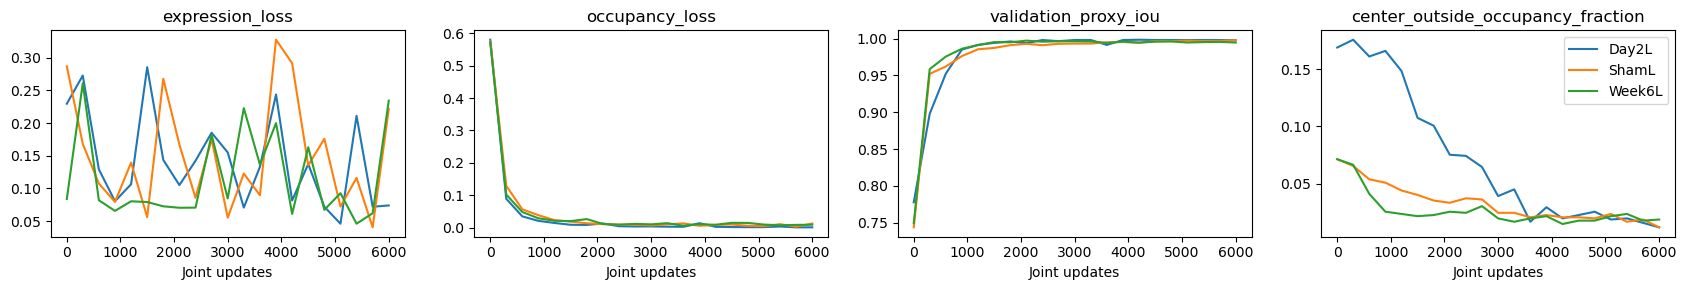

In [5]:
occ_model = None
if emitter is None:
    print('Load the completed expression emitter above before training occupancy.')
else:
    occ_provenance = dict(base_run=RUN_ID, base_checkpoint_sha256=sha256(CHECKPOINT),
        expression_provenance=provenance, occupancy=OCC_CFG,
        code={p: sha256(PROJECT_ROOT/p) for p in ['paper/kidney_iri_occupancy.py', 'paper/cohort_occupancy.py']})
    OCC_RUN = hashlib.sha256(json.dumps(occ_provenance, sort_keys=True).encode()).hexdigest()[:12]
    OCC_OUTPUT = data_directory()/'processed/kidney_iri_occupancy'/OCC_RUN
    OCC_FIGURES = PROJECT_ROOT/'figures/kidney_iri_occupancy'/OCC_RUN
    OCC_CHECKPOINT = PROJECT_ROOT/'notebooks/checkpoints/kidney_iri_occupancy'/OCC_RUN/'joint.pt'
    print('Joint checkpoint:', OCC_CHECKPOINT)
    occ_model, occ_history = run_joint(emitter, records, regions, occ_grid, occ_targets, cfg, OCC_CFG,
        OCC_CHECKPOINT, occ_provenance, train=RUN_OCCUPANCY, force=FORCE_OCCUPANCY_RETRAIN)
    if occ_model is not None:
        OCC_OUTPUT.mkdir(parents=True, exist_ok=True)
        OCC_FIGURES.mkdir(parents=True, exist_ok=True)
        (OCC_OUTPUT/'manifest.json').write_text(json.dumps(occ_provenance, indent=2))
        occ_history.to_csv(OCC_OUTPUT/'training_history.csv', index=False)
        fig, axes = plt.subplots(1, 4, figsize=(17, 3))
        for ax, metric in zip(axes, ['expression_loss', 'occupancy_loss', 'validation_proxy_iou', 'center_outside_occupancy_fraction']):
            for sample, group in occ_history.groupby('sample'):
                ax.plot(group['total_updates'], group[metric], label=sample)
            ax.set(xlabel='Joint updates', title=metric)
        axes[-1].legend(); fig.tight_layout()
        fig.savefig(OCC_FIGURES/'training.png', dpi=180); plt.show()


## Joint endpoint reconstruction

These metrics use the final joint model at the original measurement coordinates, without occupancy masking.
Independent fields and the section mean remain numerical baselines. Regional figures compare observed expression,
independent splats and the joint model, never the pre-occupancy emitter.
Higher cosine and lower MAE are better; deltas are joint minus independent. These are in-sample endpoint metrics.
Expression MAE is in averaged log1p-count units; log-total MAE uses sums of transformed expression, not raw counts.


In [6]:
endpoint_values = {}
if occ_model is not None:
    metrics, endpoint_values = compare_endpoints(occ_model, reference['independent'], records, regions,
        cfg['widths_um'], batch_size=cfg['render_batch_size'])
    metrics['method'] = metrics['method'].replace({'Emitter': 'Joint model'})
    endpoint_values = {key: {('Joint model' if name == 'Emitter' else name): value
        for name, value in values.items()} for key, values in endpoint_values.items()}
    metrics.to_csv(OCC_OUTPUT/'regional_metrics.csv', index=False)
    display(metrics)
    metric_names = ['profile_cosine', 'expression_mae', 'log_total_mae']
    indexed = metrics.set_index(['sample', 'width_um', 'method'])[metric_names]
    delta = indexed.xs('Joint model', level='method')-indexed.xs('Independent splats', level='method')
    delta.to_csv(OCC_OUTPUT/'joint_minus_independent.csv')
    print('Joint model minus independent: positive cosine / negative error is better')
    display(delta)
    for (sample, width), values in endpoint_values.items():
        np.savez_compressed(OCC_OUTPUT/f'{sample}_{width}um_regions.npz',
            centers_um=regions[sample, width]['centers_um'], gene_ids=genes, **values)
else:
    print('Load or train the joint occupancy checkpoint before plotting results; no base-model fallback.')


,sample,width_um,method,n_regions,coverage,expression_mae,profile_cosine,log_total_mae
0,ShamL,50,Independent splats,5578,0.9968,0.06102,0.8961,0.1307
1,ShamL,50,Joint model,5578,0.9968,0.06395,0.8867,0.1416
2,ShamL,50,Section mean,5578,0.9968,0.09136,0.7775,0.2421
3,ShamL,100,Independent splats,1468,0.9995,0.03769,0.9542,0.08033
4,ShamL,100,Joint model,1468,0.9995,0.04185,0.9442,0.09445
5,ShamL,100,Section mean,1468,0.9995,0.07372,0.8289,0.2141
6,ShamL,200,Independent splats,387,0.9998,0.02058,0.9868,0.04121
7,ShamL,200,Joint model,387,0.9998,0.02546,0.9797,0.05835
8,ShamL,200,Section mean,387,0.9998,0.06145,0.8674,0.1925
9,Day2L,50,Independent splats,6021,0.9973,0.07135,0.9201,0.1162


Joint model minus independent: positive cosine / negative error is better


profile_cosine  expression_mae  log_total_mae
sample width_um                                               
ShamL  50              -0.00938        0.002929        0.01089
       100            -0.009993        0.004166        0.01412
       200            -0.007185         0.00488        0.01714
Day2L  50              -0.02125        0.008923        0.02027
       100             -0.02156         0.01161        0.02998
       200             -0.01869         0.01418        0.03838
Week6L 50              -0.00955        0.003758        0.01016
       100            -0.009348        0.004962        0.01313
       200            -0.006298        0.005732        0.01823

## Regional expression and shared states

Marker maps use the same observed-derived color range across all methods within a specimen and gene.
The five regional states and their colors are reused from the independent experiment, not reclustered.
State labels summarize regional profiles; they are not cell types. Compare both spatial placement and overall fractions:
an emitter can obtain good average cosine while overrepresenting a common state.


,state,color,enriched_genes
0,R0,#1f77b4,"Slc13a3, Slc22a8, Inmt, Cyp2e1, Slc6a19"
1,R1,#ff7f0e,"Krt15, Ccr1, Krt14, Upk1b, Ccl7"
2,R2,#2ca02c,"Slc22a19, Cyp7b1, Bcat1, Slc7a12, Agt"
3,R3,#9467bd,"Kcnt1, Tmem207, Slc14a2, Ptger3, Fst"
4,R4,#8c564b,"Trpv5, Havcr1, Slc26a4, Myom2, Aldh1l2"


Markers absent from panel: ['Lrp2', 'Slc34a1']


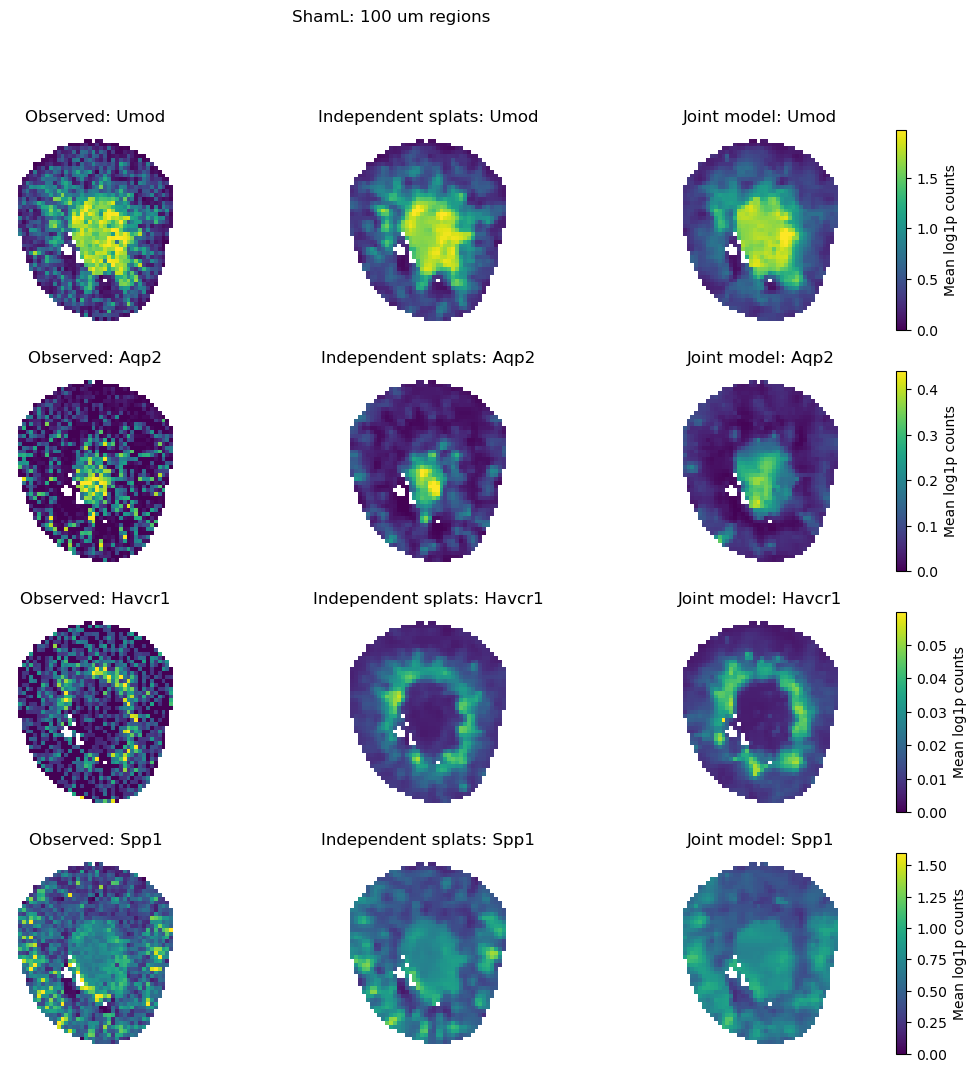

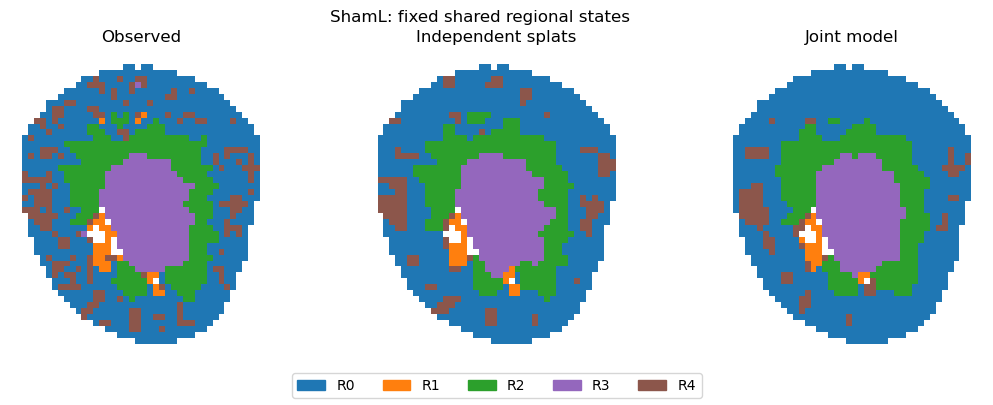

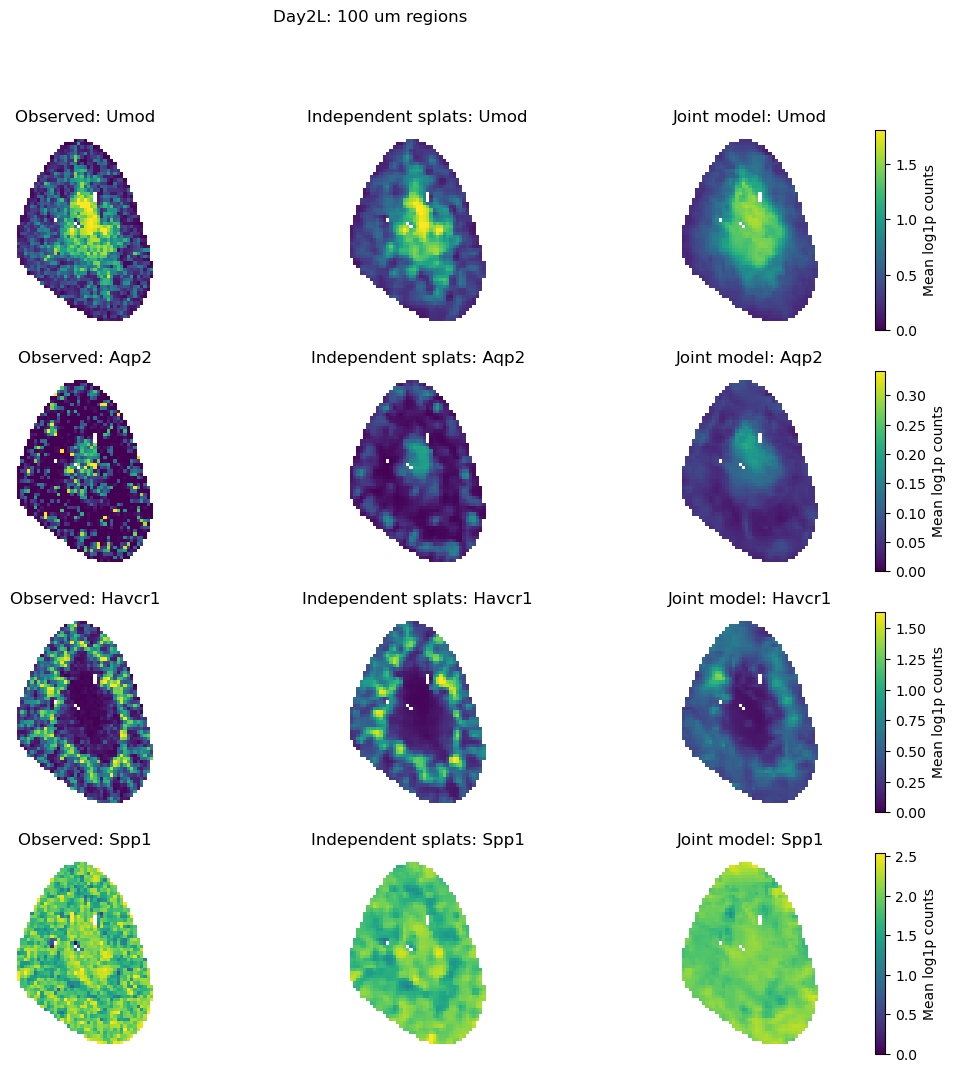

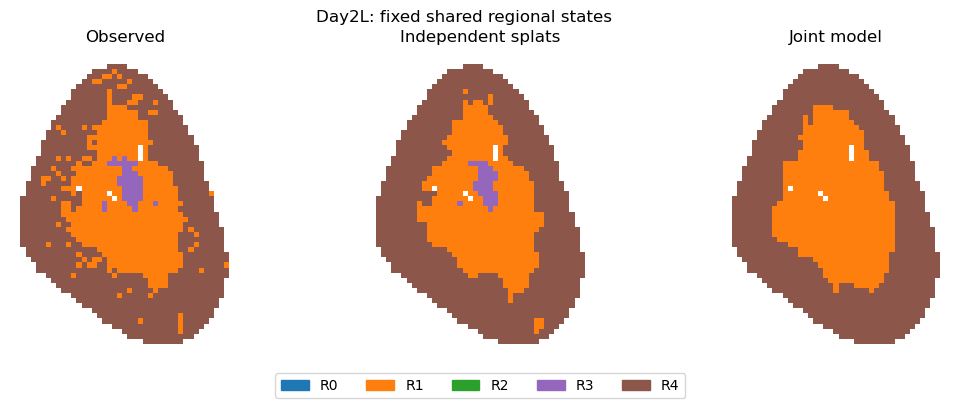

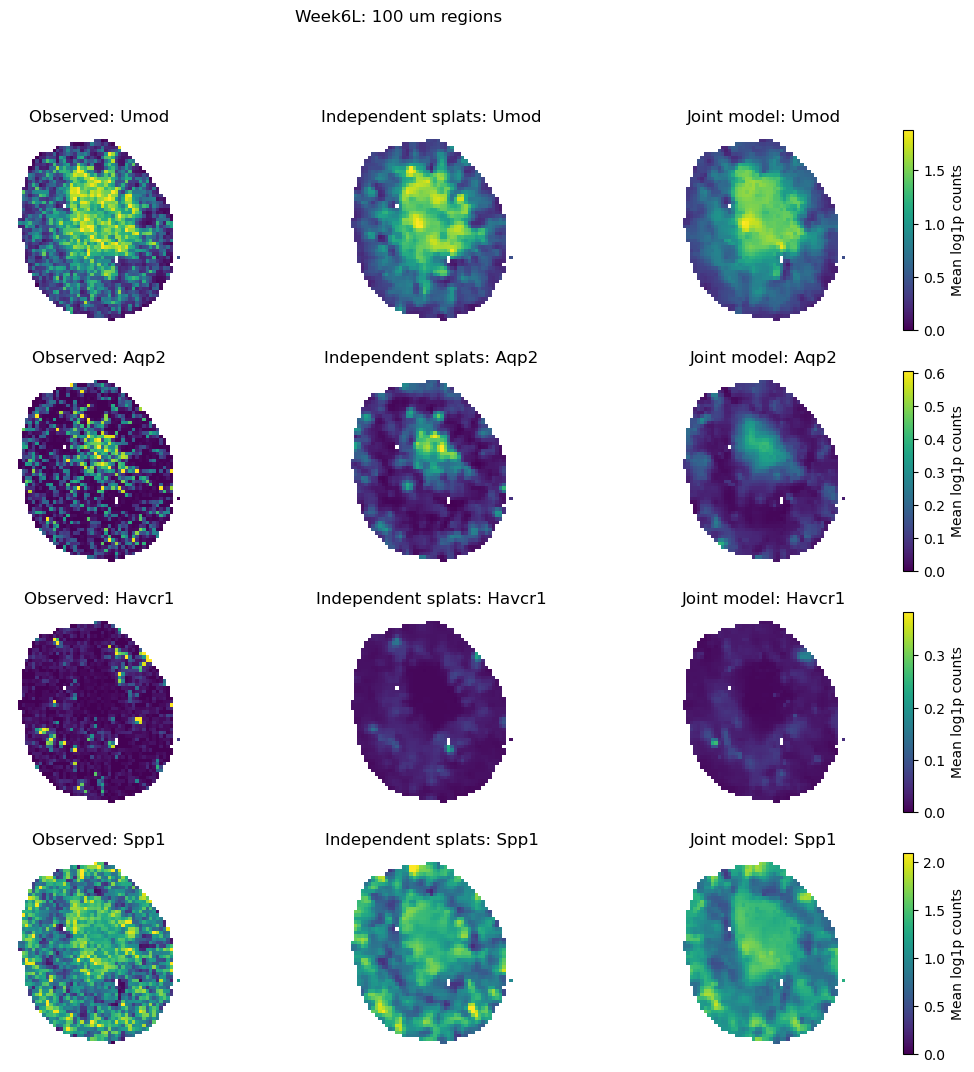

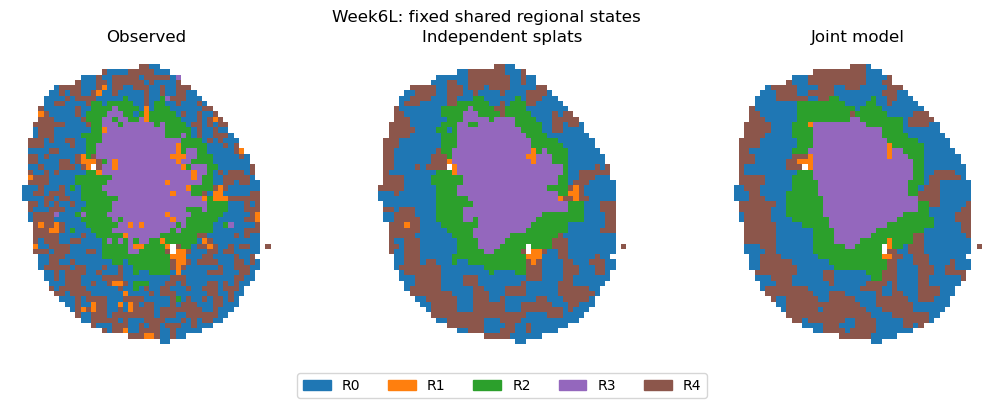

method        Independent splats  Joint model  Observed
sample state                                           
Day2L  R0                      0            0         0
       R1                 0.3357       0.3736    0.3508
       R2                      0            0         0
       R3                0.02212            0   0.02592
       R4                 0.6422       0.6264    0.6233
ShamL  R0                 0.5402       0.5668    0.4911
       R1                0.01839      0.01567    0.0218
       R2                 0.1969       0.1975    0.1969
       R3                 0.1621       0.1594    0.1601
       R4                0.08243      0.06063    0.1301
Week6L R0                 0.3811       0.3655     0.359
       R1                0.01024     0.007008   0.04097
       R2                 0.1623       0.1741    0.1617
       R3                 0.1935       0.1844    0.1817
       R4                 0.2528        0.269    0.2566

In [7]:
PLOT_WIDTH_UM = 100
MARKERS = ['Lrp2', 'Slc34a1', 'Umod', 'Aqp2', 'Havcr1', 'Spp1']
with np.load(SOURCE/'regional_state_reference.npz', allow_pickle=False) as saved_states:
    np.testing.assert_array_equal(saved_states['gene_ids'], genes)
    state_centers = saved_states['centers'].copy()
legend = pd.read_csv(SOURCE/'regional_state_legend.csv')
if len(state_centers) != len(legend) or not np.isfinite(state_centers).all():
    raise ValueError('Invalid source regional state reference')
display(legend)
state_colors = legend['color'].tolist()
cmap = ListedColormap(state_colors)
norm = BoundaryNorm(np.arange(len(state_centers)+1)-0.5, len(state_centers))
METHODS = ['Observed', 'Independent splats', 'Joint model']
def state_assignments(values):
    profile = values/np.maximum(values.sum(1, keepdims=True), 1e-8)
    return pairwise_distances_argmin(profile, state_centers)

def draw_regions(ax, xy, values, *, cmap, norm=None, vmax=None):
    offsets = PLOT_WIDTH_UM/2*np.array([[-1, -1], [1, -1], [1, 1], [-1, 1]])
    artist = PolyCollection(xy[:, None]+offsets[None], array=np.asarray(values),
        cmap=cmap, norm=norm, edgecolors='none', rasterized=True)
    if norm is None:
        artist.set_clim(0, vmax)
    ax.add_collection(artist)
    ax.autoscale_view()
    return artist

print('Markers absent from panel:', sorted(set(MARKERS)-set(genes)))

fraction_rows = []
for record in records if endpoint_values else []:
    sample = record['section']
    xy = regions[sample, PLOT_WIDTH_UM]['centers_um']
    values = endpoint_values[sample, PLOT_WIDTH_UM]
    markers = [g for g in MARKERS if g in genes]
    if markers:
        fig, axes = plt.subplots(len(markers), len(METHODS), figsize=(13, 3*len(markers)), squeeze=False)
        for row, gene in enumerate(markers):
            index = np.flatnonzero(genes == gene)[0]
            upper = max(float(np.quantile(values['Observed'][:, index], .99)), 1e-8)
            for col, method in enumerate(METHODS):
                ax = axes[row, col]
                artist = draw_regions(ax, xy, values[method][:, index], vmax=upper, cmap='viridis')
                ax.set(title=f'{method}: {gene}', aspect='equal'); ax.set_axis_off()
            fig.colorbar(artist, ax=list(axes[row]), fraction=.015, label='Mean log1p counts')
        fig.suptitle(f'{sample}: {PLOT_WIDTH_UM} um regions')
        fig.savefig(OCC_FIGURES/f'{sample}_markers.png', dpi=180, bbox_inches='tight'); plt.show()
    fig, axes = plt.subplots(1, len(METHODS), figsize=(13, 4))
    for ax, method in zip(axes, METHODS):
        labels = state_assignments(values[method])
        draw_regions(ax, xy, labels, cmap=cmap, norm=norm)
        ax.set(title=method, aspect='equal'); ax.set_axis_off()
        for state, fraction in enumerate(np.bincount(labels, minlength=len(state_centers))/len(labels)):
            fraction_rows.append(dict(sample=sample, method=method, state=f'R{state}', fraction=fraction))
    fig.legend(handles=[Patch(color=color, label=f'R{i}') for i, color in enumerate(state_colors)],
               loc='lower center', ncol=len(state_colors))
    fig.suptitle(f'{sample}: fixed shared regional states')
    fig.savefig(OCC_FIGURES/f'{sample}_states.png', dpi=180, bbox_inches='tight'); plt.show()
if fraction_rows:
    fractions = pd.DataFrame(fraction_rows)
    fractions.to_csv(OCC_OUTPUT/'regional_state_fractions.csv', index=False)
    display(fractions.pivot(index=['sample', 'state'], columns='method', values='fraction'))


## Joint primitives and model size

Expression ellipses and centers compare independent fields with the final joint model. Both panels use the
joint model's predicted occupancy as a common gray reference, in the same physical coordinate frame.
The independent fields do not predict occupancy. Ellipses show one learned scale radius, not hard tissue
boundaries; a footprint can cross the boundary even when its center is inside. Colors use the fixed shared-state
reference applied to decoded splat profiles, not new clustering.

The size table includes the complete joint model: expression emitter, occupancy heads and slots, shared condition
embeddings, frozen decoder, renderer placeholders and initialization buffers. State-tensor MiB excludes training
data, optimizer state and serialization overhead. Expression and occupancy primitives are counted separately.


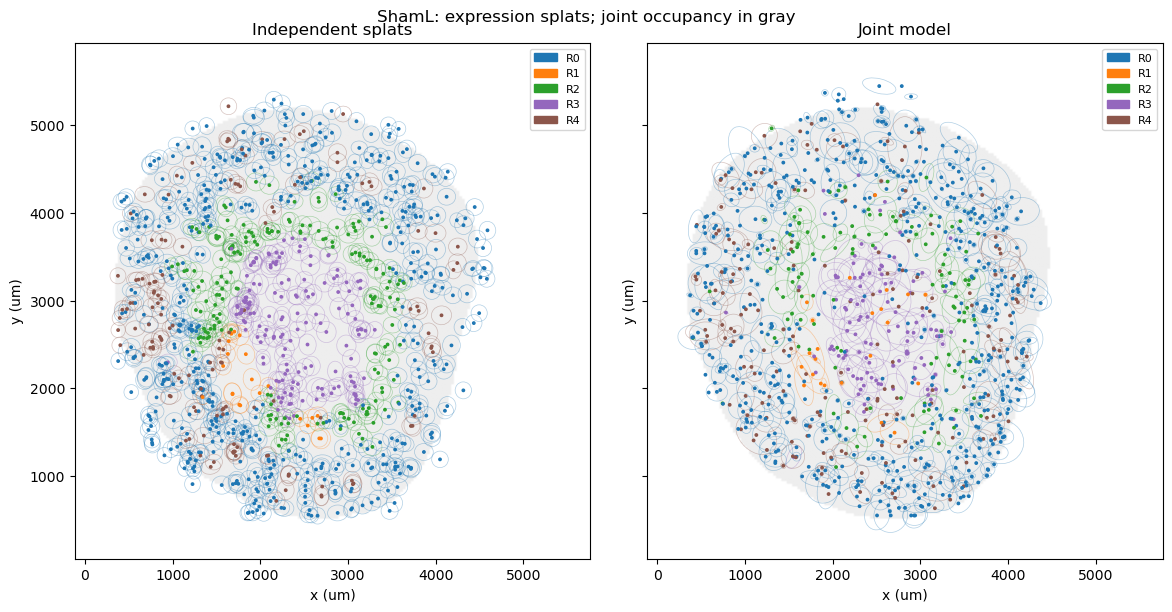

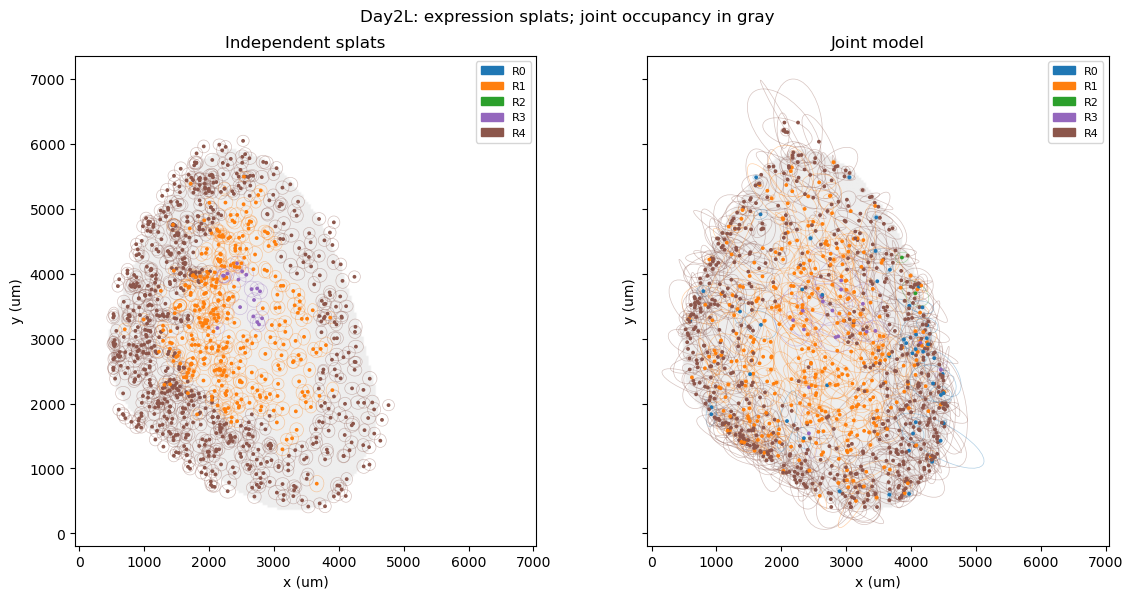

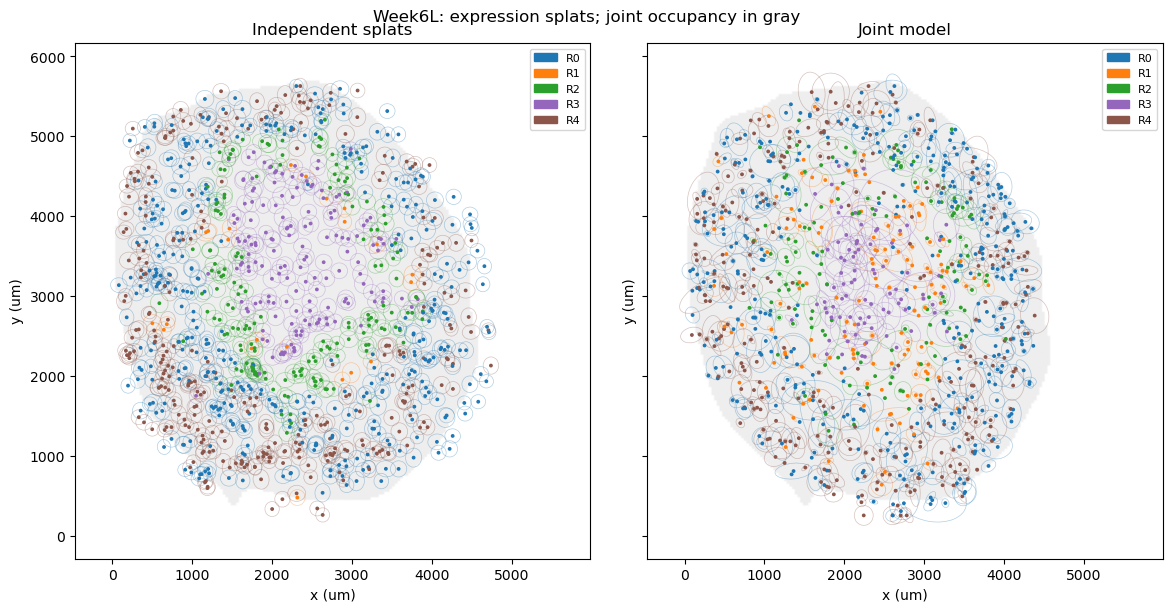

,model,expression_primitives,occupancy_primitives,parameters,trainable_parameters,state_tensor_mib
0,Joint expression + occupancy,1024,256,210441,111069,0.9415


Joint results: /data/spatsplat/data/processed/kidney_iri_occupancy/9eca165c456f
Joint figures: /home/javeda/Documents/Research/spatsplat/figures/kidney_iri_occupancy/9eca165c456f


In [8]:
if occ_model is not None:
    for record in records:
        sample, condition = record['section'], record['condition']
        fields = [('Independent splats', export_independent(reference['independent'][sample], record)),
                  ('Joint model', export_field(occ_model, condition))]
        probability = predict_occupancy(occ_model, occ_grid, condition)
        physical_grid = occ_grid*record['scale_um']+record['lower_um']
        physical_extent = [physical_grid[:, 0].min(), physical_grid[:, 0].max(),
                           physical_grid[:, 1].min(), physical_grid[:, 1].max()]
        fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharex=True, sharey=True)
        for ax, (method, field) in zip(axes, fields):
            ax.imshow((probability >= OCC_CFG['threshold']).reshape(size, size), origin='lower',
                extent=physical_extent, cmap=ListedColormap(['white', '#eeeeee']), vmin=0, vmax=1)
            centers = field['means']*record['scale_um']+record['lower_um']
            radii = np.exp(field['log_scales'])*record['scale_um']
            labels = state_assignments(field['profiles'])
            for center, radius, angle, label in zip(centers, radii, field['rotation'].ravel(), labels):
                ax.add_patch(Ellipse(center, 2*radius[0], 2*radius[1], angle=np.degrees(angle),
                    facecolor='none', edgecolor=state_colors[label], alpha=.35, linewidth=.5))
            ax.scatter(*centers.T, c=[state_colors[label] for label in labels], s=3)
            ax.set(title=method, aspect='equal',
                xlabel='x (um)', ylabel='y (um)')
            ax.legend(handles=[Patch(color=color, label=f'R{i}') for i, color in enumerate(state_colors)],
                      loc='upper right', fontsize=8)
        fig.suptitle(f'{sample}: expression splats; joint occupancy in gray')
        fig.tight_layout(); fig.savefig(OCC_FIGURES/f'{sample}_splats.png', dpi=180); plt.show()
    budgets = pd.DataFrame([dict(model='Joint expression + occupancy',
        expression_primitives=occ_model.base.slots.num_embeddings,
        occupancy_primitives=occ_model.occupancy_slots.num_embeddings,
        parameters=sum(p.numel() for p in occ_model.parameters()),
        trainable_parameters=sum(p.numel() for p in occ_model.parameters() if p.requires_grad),
        state_tensor_mib=sum(t.numel()*t.element_size() for t in occ_model.state_dict().values())/1024**2)])
    display(budgets)
    budgets.to_csv(OCC_OUTPUT/'model_budgets.csv', index=False)
    print('Joint results:', OCC_OUTPUT)
    print('Joint figures:', OCC_FIGURES)


## Joint occupancy and canvas expression

All outputs below come from the same final joint model used above. Center exterior fractions and one-scale
ellipse-perimeter exterior fractions are measured against fixed reference support, not against the predicted mask.
Unknown fractions are reported separately. Perimeter fractions are geometric diagnostics, not Gaussian tail mass.

Marker maps query a regular canvas rather than only observed coordinates. Binary masking is for display;
probability-weighted expression is also exported but changes intensities at uncertain boundaries. Neither is used
in the unmasked regional metrics above. Block occupancy scores are reference-proxy monitoring diagnostics.


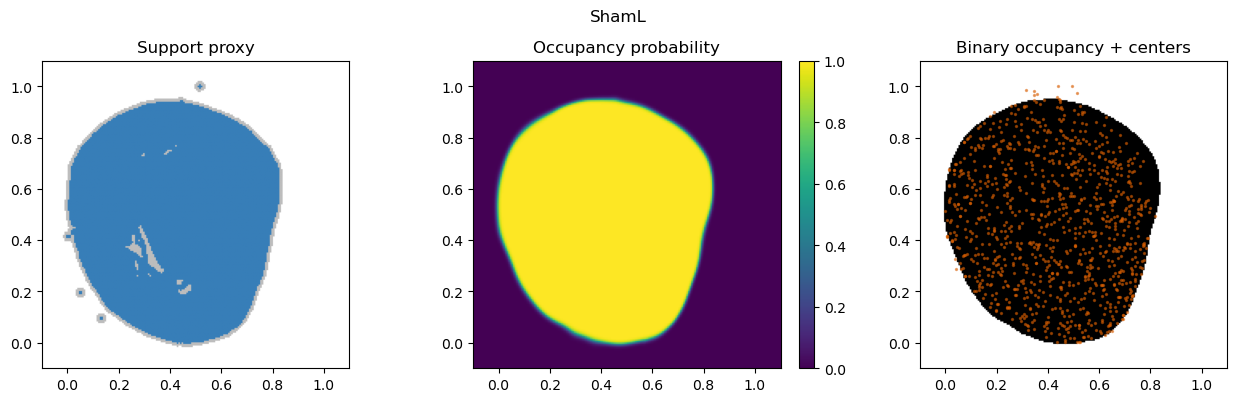

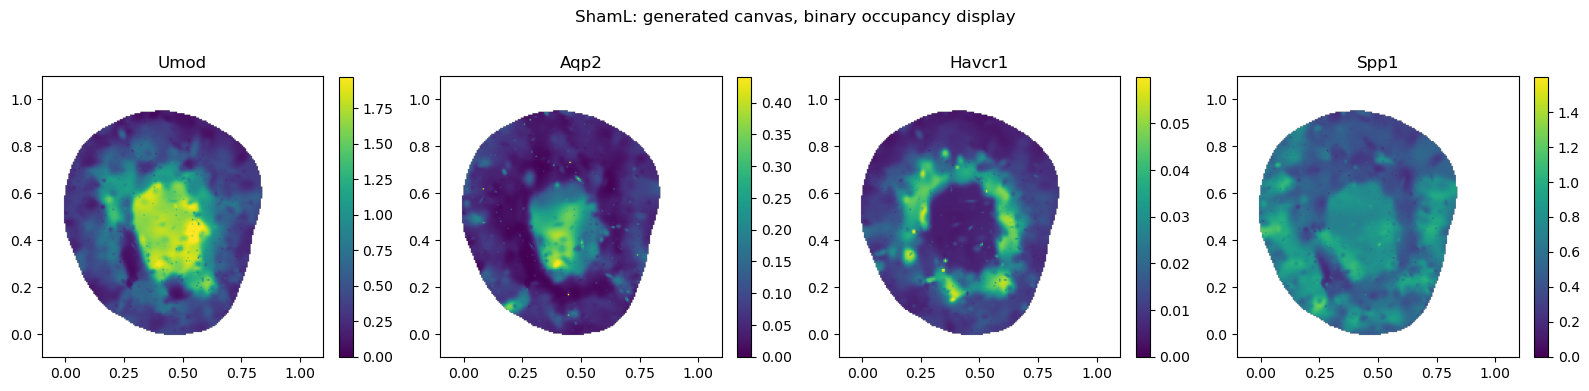

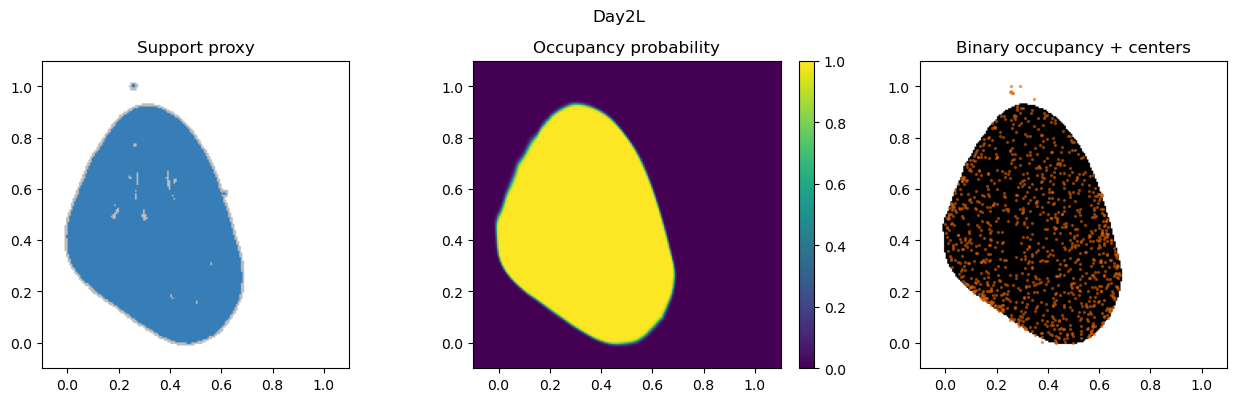

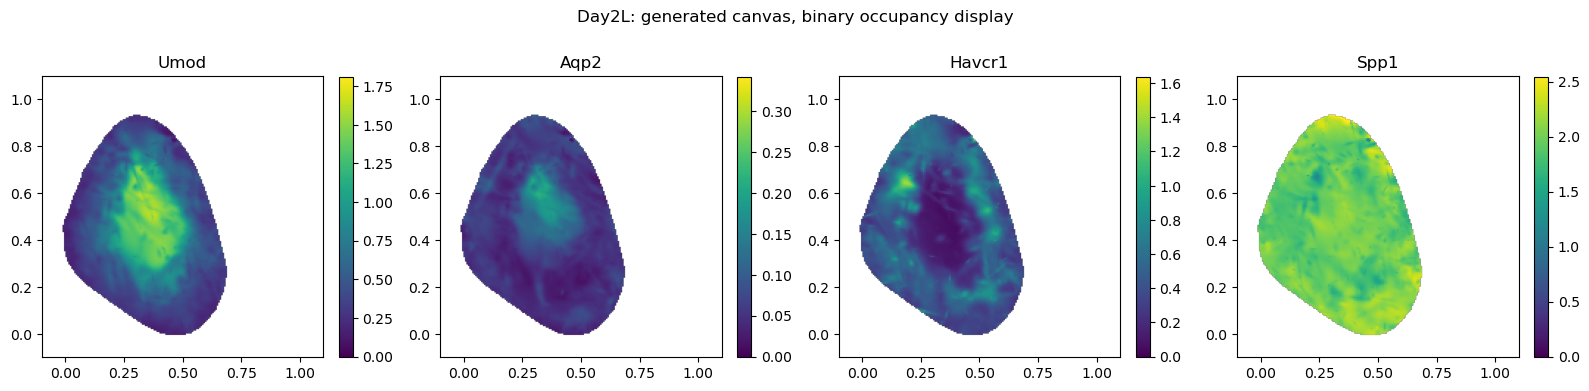

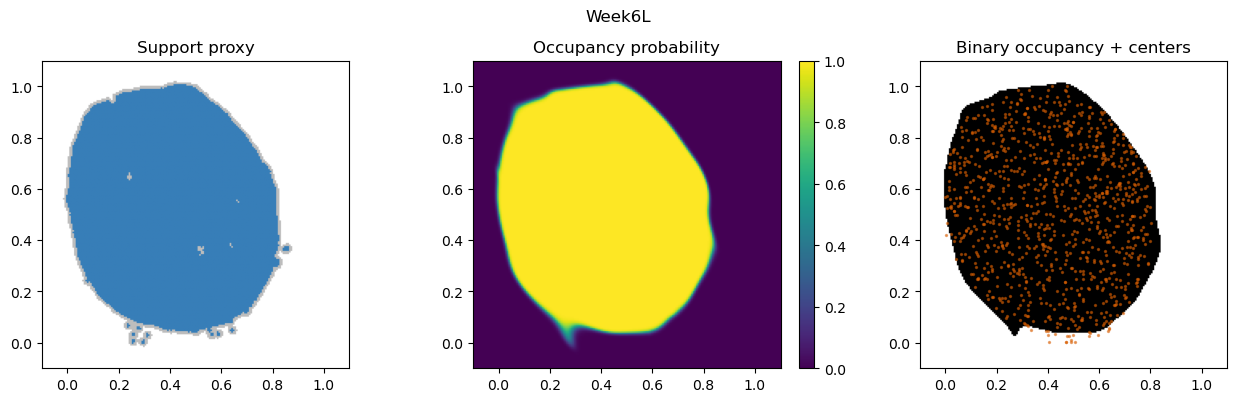

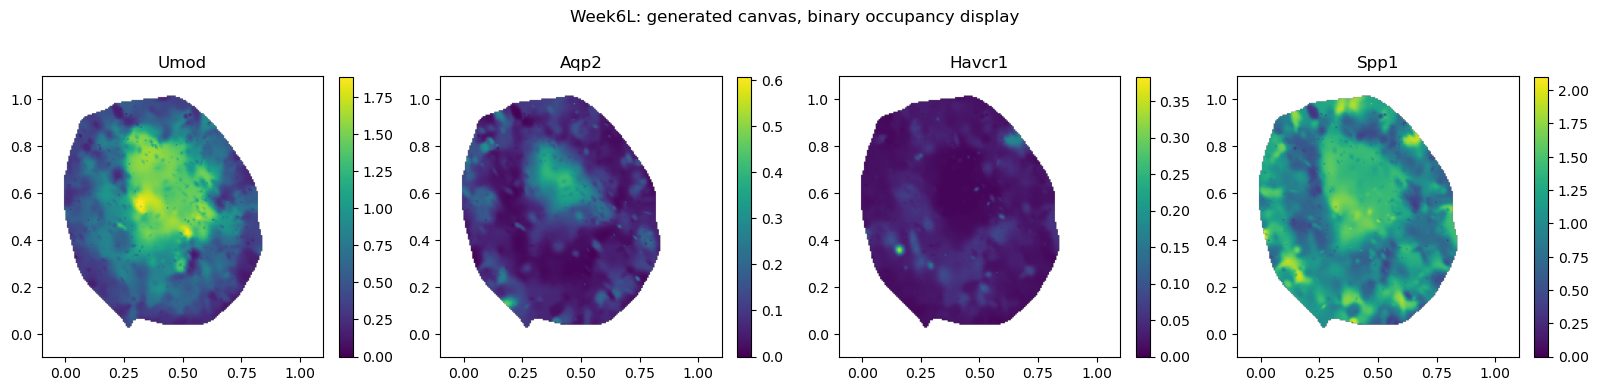

,sample,split,n,bce,brier,proxy_iou,proxy_dice,positive_recall,exterior_false_positive_fraction
0,ShamL,train,28405,0.007203,0.0009101,0.9988,0.9994,0.9989,6.154e-05
1,ShamL,validation,7237,0.01048,0.001367,0.9975,0.9988,0.9984,0.0007459
2,Day2L,train,28858,0.002582,0.00023,0.9998,0.9999,0.9998,0
3,Day2L,validation,7239,0.007662,0.0009696,0.9976,0.9988,0.998,0.0002123
4,Week6L,train,28612,0.008276,0.002046,0.9948,0.9974,0.9966,0.001374
5,Week6L,validation,7159,0.008088,0.002189,0.9946,0.9973,0.9983,0.003569


,sample,method,center_exterior_fraction,center_unknown_fraction,one_scale_perimeter_exterior_fraction,one_scale_perimeter_unknown_fraction
0,ShamL,Joint model,0.009766,0.02148,0.01804,0.03336
1,Day2L,Joint model,0.006836,0.02734,0.05838,0.05258
2,Week6L,Joint model,0.01074,0.0127,0.0184,0.01953


In [9]:
if occ_model is not None:
    support_rows, occupancy_rows = [], []
    for record in records:
        sample, condition = record['section'], record['condition']
        target = occ_targets[sample]
        probability = predict_occupancy(occ_model, occ_grid, condition)
        for split in ['train', 'validation']:
            occupancy_rows.append(dict(sample=sample, split=split,
                **occupancy_metrics(probability, target['labels'], target[split], OCC_CFG['threshold'])))
        for method, model in [('Joint model', occ_model)]:
            support_rows.append(dict(sample=sample, method=method,
                **geometry_support_summary(model, record, occ_grid, target, size)))
        raw = predict_field(occ_model, occ_grid, condition, batch_size=cfg['render_batch_size'])
        mask = probability >= OCC_CFG['threshold']
        np.savez_compressed(OCC_OUTPUT/f'{sample}_canvas.npz', xy=occ_grid,
            gene_ids=genes, lower_um=record['lower_um'], scale_um=record['scale_um'],
            occupancy_probability=probability, binary_mask=mask, threshold=OCC_CFG['threshold'],
            expression_unmasked=raw, expression_binary_masked=raw*mask[:, None],
            expression_probability_weighted=raw*probability[:, None],
            proxy_labels=target['labels'], proxy_train=target['train'], proxy_validation=target['validation'],
            expression_kind='log1p_measured_counts')
        emitted = export_field(occ_model, condition)
        with torch.no_grad():
            occupancy_parameters = {f'occupancy_{k}': v.detach().cpu().numpy()
                for k, v in occ_model.emit_occupancy(condition).items()}
        np.savez_compressed(OCC_OUTPUT/f'{sample}_joint_splats.npz', **emitted, **occupancy_parameters,
            gene_ids=genes, lower_um=record['lower_um'], scale_um=record['scale_um'],
            kernel_sharpness=cfg['kernel_sharpness'], condition_label=sample)
        fig, axes = plt.subplots(1, 3, figsize=(13, 4))
        axes[0].imshow(target['labels'].reshape(size, size), origin='lower', extent=extent,
            cmap=ListedColormap(['#bdbdbd', '#ffffff', '#377eb8']), vmin=-1, vmax=1)
        image = axes[1].imshow(probability.reshape(size, size), origin='lower', extent=extent, vmin=0, vmax=1)
        fig.colorbar(image, ax=axes[1], fraction=.045)
        axes[2].imshow(mask.reshape(size, size), origin='lower', extent=extent, cmap='gray_r', vmin=0, vmax=1)
        axes[2].scatter(*emitted['means'].T, s=2, color='#d95f02', alpha=.5)
        for ax, title in zip(axes, ['Support proxy', 'Occupancy probability', 'Binary occupancy + centers']):
            ax.set(title=title, aspect='equal')
        fig.suptitle(sample); fig.tight_layout()
        fig.savefig(OCC_FIGURES/f'{sample}_occupancy.png', dpi=180); plt.show()
        markers = [g for g in MARKERS if g in genes]
        if markers:
            fig, axes = plt.subplots(1, len(markers), figsize=(4*len(markers), 4), squeeze=False)
            observed = regions[sample, PLOT_WIDTH_UM]['values']['Observed']
            for ax, gene in zip(axes.ravel(), markers):
                index = np.flatnonzero(genes == gene)[0]
                values = np.ma.array(raw[:, index].reshape(size, size), mask=~mask.reshape(size, size))
                im = ax.imshow(values, origin='lower', extent=extent, cmap='viridis', vmin=0,
                    vmax=max(float(np.quantile(observed[:, index], .99)), 1e-8))
                ax.set(title=gene, aspect='equal'); fig.colorbar(im, ax=ax, fraction=.045)
            fig.suptitle(f'{sample}: generated canvas, binary occupancy display')
            fig.tight_layout(); fig.savefig(OCC_FIGURES/f'{sample}_masked_markers.png', dpi=180); plt.show()
    occupancy_table, support_table = pd.DataFrame(occupancy_rows), pd.DataFrame(support_rows)
    occupancy_table.to_csv(OCC_OUTPUT/'occupancy_proxy_metrics.csv', index=False)
    support_table.to_csv(OCC_OUTPUT/'geometry_support.csv', index=False)
    display(occupancy_table); display(support_table)


## Exploratory embedding blends

Interpolate the learned ShamL and Day2L embeddings, then emit both branches without fitting anything.
Fractions are positions in embedding space, **not time, disease severity, or fractions of cells mixed together**.
These are deterministic synthetic transitions, not samples from a learned distribution of biological variability.
The tissues are unregistered and animal identity is confounded with state. Intermediate shapes and expression
have no ground-truth targets, so the plots diagnose behavior rather than validate a progression model.

All panels share a normalized canvas. Physical scale and origin metadata are linearly interpolated explicitly;
they are not generated. The scale also enters the emitter's physical radius bounds. Endpoint emission parameters
are checked exactly, and endpoint expression/occupancy are checked on identical sampled canvas coordinates.
Only condition embeddings and physical metadata are interpolated: neither rendered images nor emitted splats
are averaged. The categorical training objective did not constrain this path to be meaningful or smooth.


In [10]:
from paper.kidney_iri_blending import render_blend, blend_summary, check_endpoints

BLEND_LEFT = 'ShamL'
BLEND_RIGHT = 'Day2L'
BLEND_FRACTIONS = [0., .25, .5, .75, 1.]
BLEND_REGION_WIDTH_UM = 100
blend_results = []
if occ_model is None:
    print('Load the completed joint model first; blending never trains a model.')
else:
    lookup = {r['section']: r for r in records}
    left, right = lookup[BLEND_LEFT], lookup[BLEND_RIGHT]
    if not BLEND_FRACTIONS or any(not np.isfinite(a) or not 0 <= a <= 1 for a in BLEND_FRACTIONS):
        raise ValueError('Choose blend fractions between zero and one')
    probe = occ_grid[np.linspace(0, len(occ_grid)-1, min(512, len(occ_grid)), dtype=int)]
    check_endpoints(occ_model, left['condition'], right['condition'], probe,
                    batch_size=cfg['render_batch_size'])
    print('Both endpoints reproduce joint emission parameters and rendered probes exactly.')
    blend_settings = dict(joint_run=OCC_RUN, checkpoint_sha256=sha256(OCC_CHECKPOINT),
        left=BLEND_LEFT, right=BLEND_RIGHT, fractions=BLEND_FRACTIONS,
        canvas_size=size, threshold=OCC_CFG['threshold'], region_width_um=BLEND_REGION_WIDTH_UM,
        helper_sha256=sha256(PROJECT_ROOT/'paper/kidney_iri_blending.py'))
    BLEND_ID = hashlib.sha256(json.dumps(blend_settings, sort_keys=True).encode()).hexdigest()[:12]
    BLEND_OUTPUT = OCC_OUTPUT/'blends'/BLEND_ID
    BLEND_OUTPUT.mkdir(parents=True, exist_ok=True)
    (BLEND_OUTPUT/'manifest.json').write_text(json.dumps(blend_settings, indent=2))
    blend_rows, state_rows = [], []
    for index, fraction in enumerate(BLEND_FRACTIONS):
        rendered = render_blend(occ_model, left, right, fraction, occ_grid,
                                batch_size=cfg['render_batch_size'])
        rendered['fraction'] = fraction
        blend_results.append(rendered)
        summary, state_fraction = blend_summary(rendered, occ_grid, size, OCC_CFG['threshold'],
            state_centers, BLEND_REGION_WIDTH_UM)
        blend_rows.append(dict(fraction=fraction, **summary))
        state_rows.extend(dict(fraction=fraction, state=f'R{k}', region_fraction=value)
                          for k, value in enumerate(state_fraction))
        field = {key: value for key, value in rendered['field'].items() if key != 'depth'}
        np.savez_compressed(BLEND_OUTPUT/f'blend_{index:02d}.npz', fraction=fraction,
            left=BLEND_LEFT, right=BLEND_RIGHT, gene_ids=genes, xy=occ_grid,
            lower_um=rendered['lower_um'], scale_um=rendered['scale_um'],
            kernel_sharpness=cfg['kernel_sharpness'], expression_kind='log1p_measured_counts',
            threshold=OCC_CFG['threshold'], occupancy_probability=rendered['probability'],
            binary_mask=rendered['probability'] >= OCC_CFG['threshold'],
            expression_unmasked=rendered['expression'], **field, **rendered['occupancy'])
        print(f'Blend {fraction:.4g}: occupied fraction={summary["occupied_canvas_fraction"]:.4g}, '
              f'centers outside={summary["centers_outside_occupancy"]:.4g}')
    blend_table = pd.DataFrame(blend_rows)
    blend_states = pd.DataFrame(state_rows)
    blend_table.to_csv(BLEND_OUTPUT/'geometry.csv', index=False)
    blend_states.to_csv(BLEND_OUTPUT/'regional_state_fractions.csv', index=False)
    display(blend_table)


Both endpoints reproduce joint emission parameters and rendered probes exactly.
Blend 0: occupied fraction=0.4369, centers outside=0.01172
Blend 0.25: occupied fraction=0.417, centers outside=0.01758
Blend 0.5: occupied fraction=0.3904, centers outside=0.02441
Blend 0.75: occupied fraction=0.3548, centers outside=0.01855
Blend 1: occupied fraction=0.3176, centers outside=0.01172


,fraction,occupied_canvas_fraction,approximate_area_mm2,connected_components,largest_component_fraction,centers_outside_occupancy,occupied_regions
0,0,0.4369,15.27,1,1,0.01172,1585
1,0.25,0.417,16.14,1,1,0.01758,1679
2,0.5,0.3904,16.66,1,1,0.02441,1722
3,0.75,0.3548,16.61,1,1,0.01855,1718
4,1,0.3176,16.25,1,1,0.01172,1692


### Synthetic transition maps

Occupancy probabilities are shown without thresholding. Marker expression is displayed only where predicted
occupancy is at least 0.5, using one color range per gene across all fractions. Color limits come from observed
endpoint regional expression; saturated colors can hide overshoot, so the marker table below also reports maxima.

Regional-state fractions use equally weighted occupied 100 um regions of the **generated regular canvas**, including
partially occupied regions. They are not measurement-weighted and need not equal the earlier observed-coordinate
summaries. Empty generated tissue gives undefined state fractions. Components use four-neighbor connectivity with
no removal of small islands. Tissue area is a raster approximation using interpolated physical scale, not a learned
physical-size prediction. A coherent-looking blend is a prototype result, not evidence of biological progression.


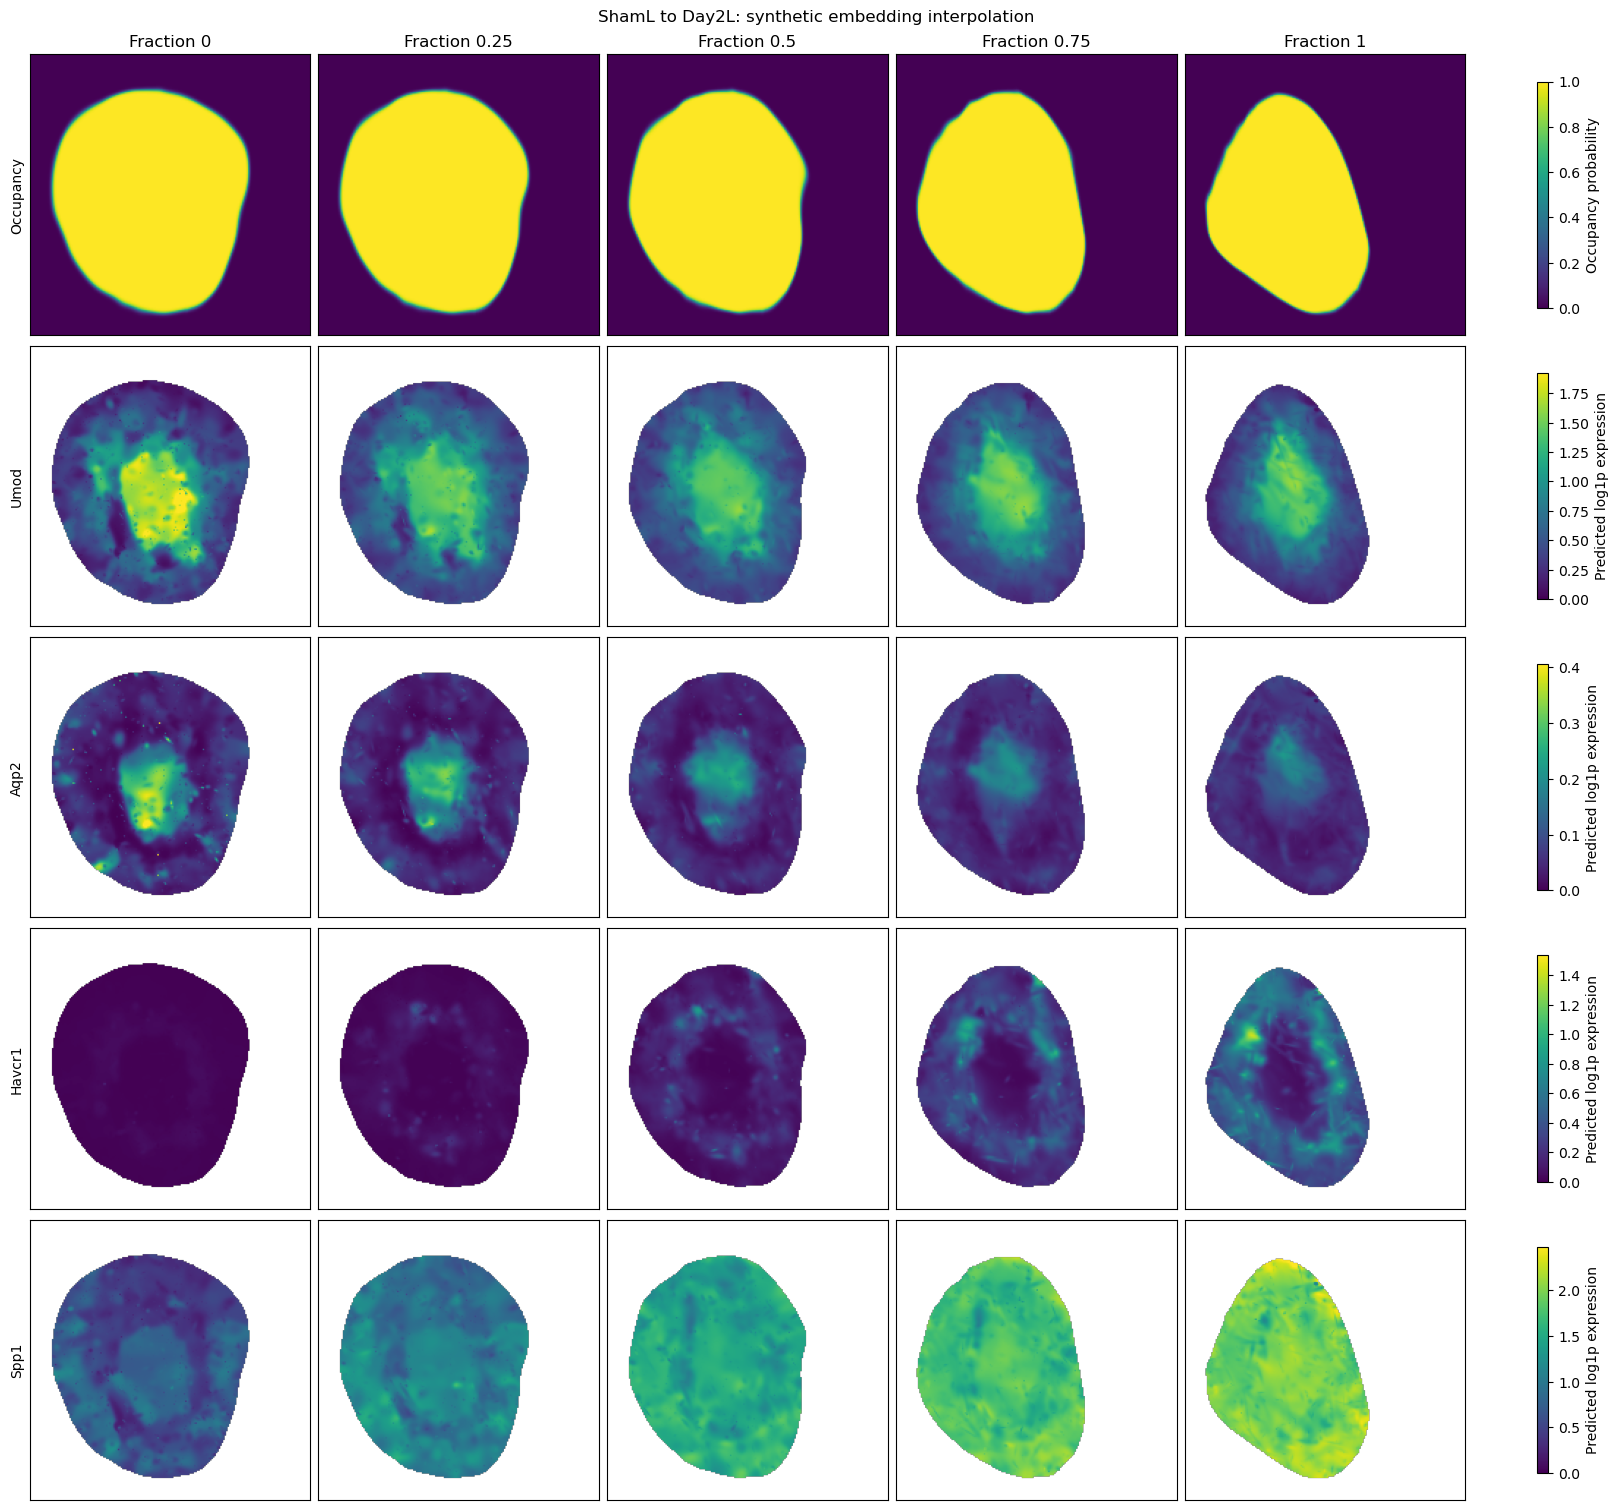

,fraction,gene,occupied_mean,occupied_max
0,0,Umod,0.6948,2.223
1,0.25,Umod,0.7399,1.68
2,0.5,Umod,0.7196,1.617
3,0.75,Umod,0.6892,1.603
4,1,Umod,0.6502,1.634
5,0,Aqp2,0.08088,0.5172
6,0.25,Aqp2,0.06762,0.3529
7,0.5,Aqp2,0.06293,0.2562
8,0.75,Aqp2,0.06485,0.2147
9,1,Aqp2,0.06497,0.219


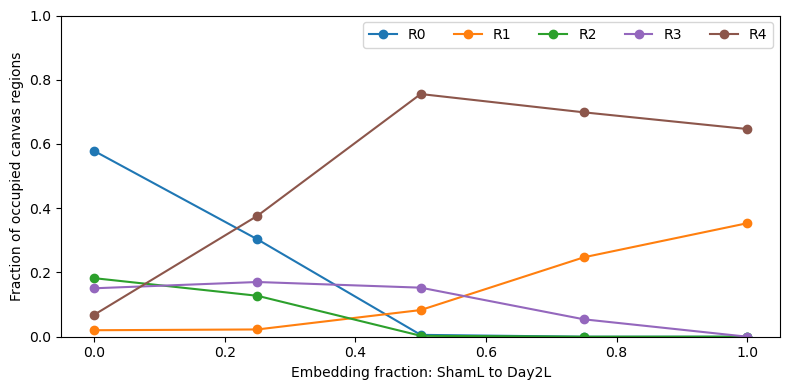

Blend outputs: /data/spatsplat/data/processed/kidney_iri_occupancy/9eca165c456f/blends/b49d3d991498


In [11]:
if blend_results:
    markers = [g for g in MARKERS if g in genes]
    fig, axes = plt.subplots(1+len(markers), len(blend_results),
        figsize=(3*len(blend_results)+1, 3*(1+len(markers))), squeeze=False, layout='constrained')
    marker_rows = []
    for col, rendered in enumerate(blend_results):
        image = axes[0, col].imshow(rendered['probability'].reshape(size, size),
            origin='lower', extent=extent, vmin=0, vmax=1, cmap='viridis')
        axes[0, col].set_title(f'Fraction {rendered["fraction"]:.4g}')
    fig.colorbar(image, ax=list(axes[0]), label='Occupancy probability', shrink=.8)
    axes[0, 0].set_ylabel('Occupancy')
    observed_endpoints = np.concatenate([regions[r['section'], PLOT_WIDTH_UM]['values']['Observed']
                                         for r in [left, right]])
    for row, gene in enumerate(markers, start=1):
        gene_index = np.flatnonzero(genes == gene)[0]
        upper = max(float(np.quantile(observed_endpoints[:, gene_index], .99)), 1e-8)
        for col, rendered in enumerate(blend_results):
            mask = rendered['probability'] >= OCC_CFG['threshold']
            values = rendered['expression'][:, gene_index]
            shown = np.ma.array(values.reshape(size, size), mask=~mask.reshape(size, size))
            image = axes[row, col].imshow(shown, origin='lower', extent=extent,
                cmap='viridis', vmin=0, vmax=upper)
            marker_rows.append(dict(fraction=rendered['fraction'], gene=gene,
                occupied_mean=float(values[mask].mean()) if mask.any() else np.nan,
                occupied_max=float(values[mask].max()) if mask.any() else np.nan))
        axes[row, 0].set_ylabel(gene)
        fig.colorbar(image, ax=list(axes[row]), label='Predicted log1p expression', shrink=.8)
    for ax in axes.ravel():
        ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(f'{BLEND_LEFT} to {BLEND_RIGHT}: synthetic embedding interpolation')
    fig.savefig(OCC_FIGURES/f'blend_{BLEND_ID}_maps.png', dpi=180, bbox_inches='tight'); plt.show()
    marker_table = pd.DataFrame(marker_rows)
    marker_table.to_csv(BLEND_OUTPUT/'marker_summary.csv', index=False)
    display(marker_table)
    fig, ax = plt.subplots(figsize=(8, 4))
    for i, color in enumerate(state_colors):
        group = blend_states[blend_states.state == f'R{i}']
        ax.plot(group.fraction, group.region_fraction, marker='o', color=color, label=f'R{i}')
    ax.set(xlabel=f'Embedding fraction: {BLEND_LEFT} to {BLEND_RIGHT}',
        ylabel='Fraction of occupied canvas regions', ylim=(0, 1))
    ax.legend(ncol=len(state_colors)); fig.tight_layout()
    fig.savefig(OCC_FIGURES/f'blend_{BLEND_ID}_states.png', dpi=180); plt.show()
    print('Blend outputs:', BLEND_OUTPUT)


## Fixed-scaffold molecular blends

This alternative holds one endpoint's centers, radii, rotations, occupancy and physical coordinate frame fixed.
Only emitted latent profiles and amplitudes vary with the interpolated condition embedding. No optimization,
slot matching, geometry interpolation or image averaging occurs. Molecular outputs use the existing frozen expression decoder.

By default the scaffold is ShamL: fraction 0 must reproduce ShamL exactly; fraction 1 is **Day2L-conditioned
molecular attributes on the ShamL scaffold**, not a reconstruction of Day2L. Choosing Day2L as the scaffold
instead makes fraction 1 the exact anchor. Shared slot indices do not establish anatomical correspondence:
profiles can be transplanted to inappropriate locations. This diagnoses the current representation; it does
not demonstrate learned separation of anatomy and biological state or biological progression.

Compare these maps with the joint blends above. Constant shape is enforced by construction, not learned.
Regional-state fractions use the same occupied-canvas convention, now with a fixed physical frame and region
membership. Color scales use the same observed endpoint reference as the joint-blend figures.


In [12]:
from paper.kidney_iri_scaffold import render_scaffold_blend

SCAFFOLD_LEFT = BLEND_LEFT
SCAFFOLD_RIGHT = BLEND_RIGHT
SCAFFOLD_SAMPLE = SCAFFOLD_LEFT  # Either endpoint can supply the fixed scaffold.
SCAFFOLD_FRACTIONS = list(BLEND_FRACTIONS)
scaffold_results = []
if occ_model is None:
    print('Load the completed joint model first; scaffold blending never trains.')
else:
    lookup = {r['section']: r for r in records}
    scaffold_left, scaffold_right = lookup[SCAFFOLD_LEFT], lookup[SCAFFOLD_RIGHT]
    scaffold_record = lookup[SCAFFOLD_SAMPLE]
    if SCAFFOLD_SAMPLE not in (SCAFFOLD_LEFT, SCAFFOLD_RIGHT):
        raise ValueError('The scaffold must be one of the molecular endpoints')
    anchor_fraction = 0. if SCAFFOLD_SAMPLE == SCAFFOLD_LEFT else 1.
    scaffold_probe = occ_grid[np.linspace(0, len(occ_grid)-1, min(512, len(occ_grid)), dtype=int)]
    anchor_check = render_scaffold_blend(occ_model, scaffold_left, scaffold_right, scaffold_record,
        anchor_fraction, scaffold_probe, batch_size=cfg['render_batch_size'])
    np.testing.assert_array_equal(anchor_check['expression'], predict_field(occ_model, scaffold_probe,
        scaffold_record['condition'], batch_size=cfg['render_batch_size']))
    np.testing.assert_array_equal(anchor_check['probability'], predict_occupancy(occ_model, scaffold_probe,
        scaffold_record['condition'], batch_size=cfg['render_batch_size']))
    print(f'Fixed-scaffold anchor {SCAFFOLD_SAMPLE} reproduces expression and occupancy exactly.')
    scaffold_settings = dict(joint_run=OCC_RUN, checkpoint_sha256=sha256(OCC_CHECKPOINT),
        left=SCAFFOLD_LEFT, right=SCAFFOLD_RIGHT, scaffold=SCAFFOLD_SAMPLE, fractions=SCAFFOLD_FRACTIONS,
        canvas_size=size, threshold=OCC_CFG['threshold'], region_width_um=BLEND_REGION_WIDTH_UM,
        code={name: sha256(PROJECT_ROOT/'paper'/name) for name in
              ['kidney_iri_scaffold.py', 'kidney_iri_blending.py']})
    SCAFFOLD_ID = hashlib.sha256(json.dumps(scaffold_settings, sort_keys=True).encode()).hexdigest()[:12]
    SCAFFOLD_OUTPUT = OCC_OUTPUT/'scaffold_blends'/SCAFFOLD_ID
    SCAFFOLD_OUTPUT.mkdir(parents=True, exist_ok=True)
    (SCAFFOLD_OUTPUT/'manifest.json').write_text(json.dumps(scaffold_settings, indent=2))
    scaffold_rows, scaffold_state_rows = [], []
    for index, fraction in enumerate(SCAFFOLD_FRACTIONS):
        rendered = render_scaffold_blend(occ_model, scaffold_left, scaffold_right, scaffold_record,
            fraction, occ_grid, batch_size=cfg['render_batch_size'])
        for key in ['means', 'log_scales', 'rotation']:
            np.testing.assert_array_equal(rendered['field'][key], anchor_check['field'][key])
        if scaffold_results:
            np.testing.assert_array_equal(rendered['probability'], scaffold_results[0]['probability'])
            np.testing.assert_array_equal(rendered['lower_um'], scaffold_results[0]['lower_um'])
            assert rendered['scale_um'] == scaffold_results[0]['scale_um']
        rendered['fraction'] = fraction
        scaffold_results.append(rendered)
        summary, state_fraction = blend_summary(rendered, occ_grid, size, OCC_CFG['threshold'],
            state_centers, BLEND_REGION_WIDTH_UM)
        scaffold_rows.append(dict(fraction=fraction, **summary))
        scaffold_state_rows.extend(dict(fraction=fraction, state=f'R{k}', region_fraction=value)
            for k, value in enumerate(state_fraction))
        field = {key: value for key, value in rendered['field'].items() if key != 'depth'}
        np.savez_compressed(SCAFFOLD_OUTPUT/f'blend_{index:02d}.npz', fraction=fraction,
            scaffold=SCAFFOLD_SAMPLE, left=SCAFFOLD_LEFT, right=SCAFFOLD_RIGHT, gene_ids=genes, xy=occ_grid,
            lower_um=rendered['lower_um'], scale_um=rendered['scale_um'],
            kernel_sharpness=cfg['kernel_sharpness'], expression_kind='log1p_measured_counts',
            threshold=OCC_CFG['threshold'], occupancy_probability=rendered['probability'],
            binary_mask=rendered['probability'] >= OCC_CFG['threshold'],
            expression_unmasked=rendered['expression'], **field, **rendered['occupancy'])
    scaffold_table = pd.DataFrame(scaffold_rows)
    scaffold_states = pd.DataFrame(scaffold_state_rows)
    scaffold_table.to_csv(SCAFFOLD_OUTPUT/'geometry.csv', index=False)
    scaffold_states.to_csv(SCAFFOLD_OUTPUT/'regional_state_fractions.csv', index=False)
    display(scaffold_table)
    print('Geometry, occupancy probabilities and physical frame are identical across fractions.')


Fixed-scaffold anchor ShamL reproduces expression and occupancy exactly.


,fraction,occupied_canvas_fraction,approximate_area_mm2,connected_components,largest_component_fraction,centers_outside_occupancy,occupied_regions
0,0,0.4369,15.27,1,1,0.01172,1585
1,0.25,0.4369,15.27,1,1,0.01172,1585
2,0.5,0.4369,15.27,1,1,0.01172,1585
3,0.75,0.4369,15.27,1,1,0.01172,1585
4,1,0.4369,15.27,1,1,0.01172,1585


Geometry, occupancy probabilities and physical frame are identical across fractions.


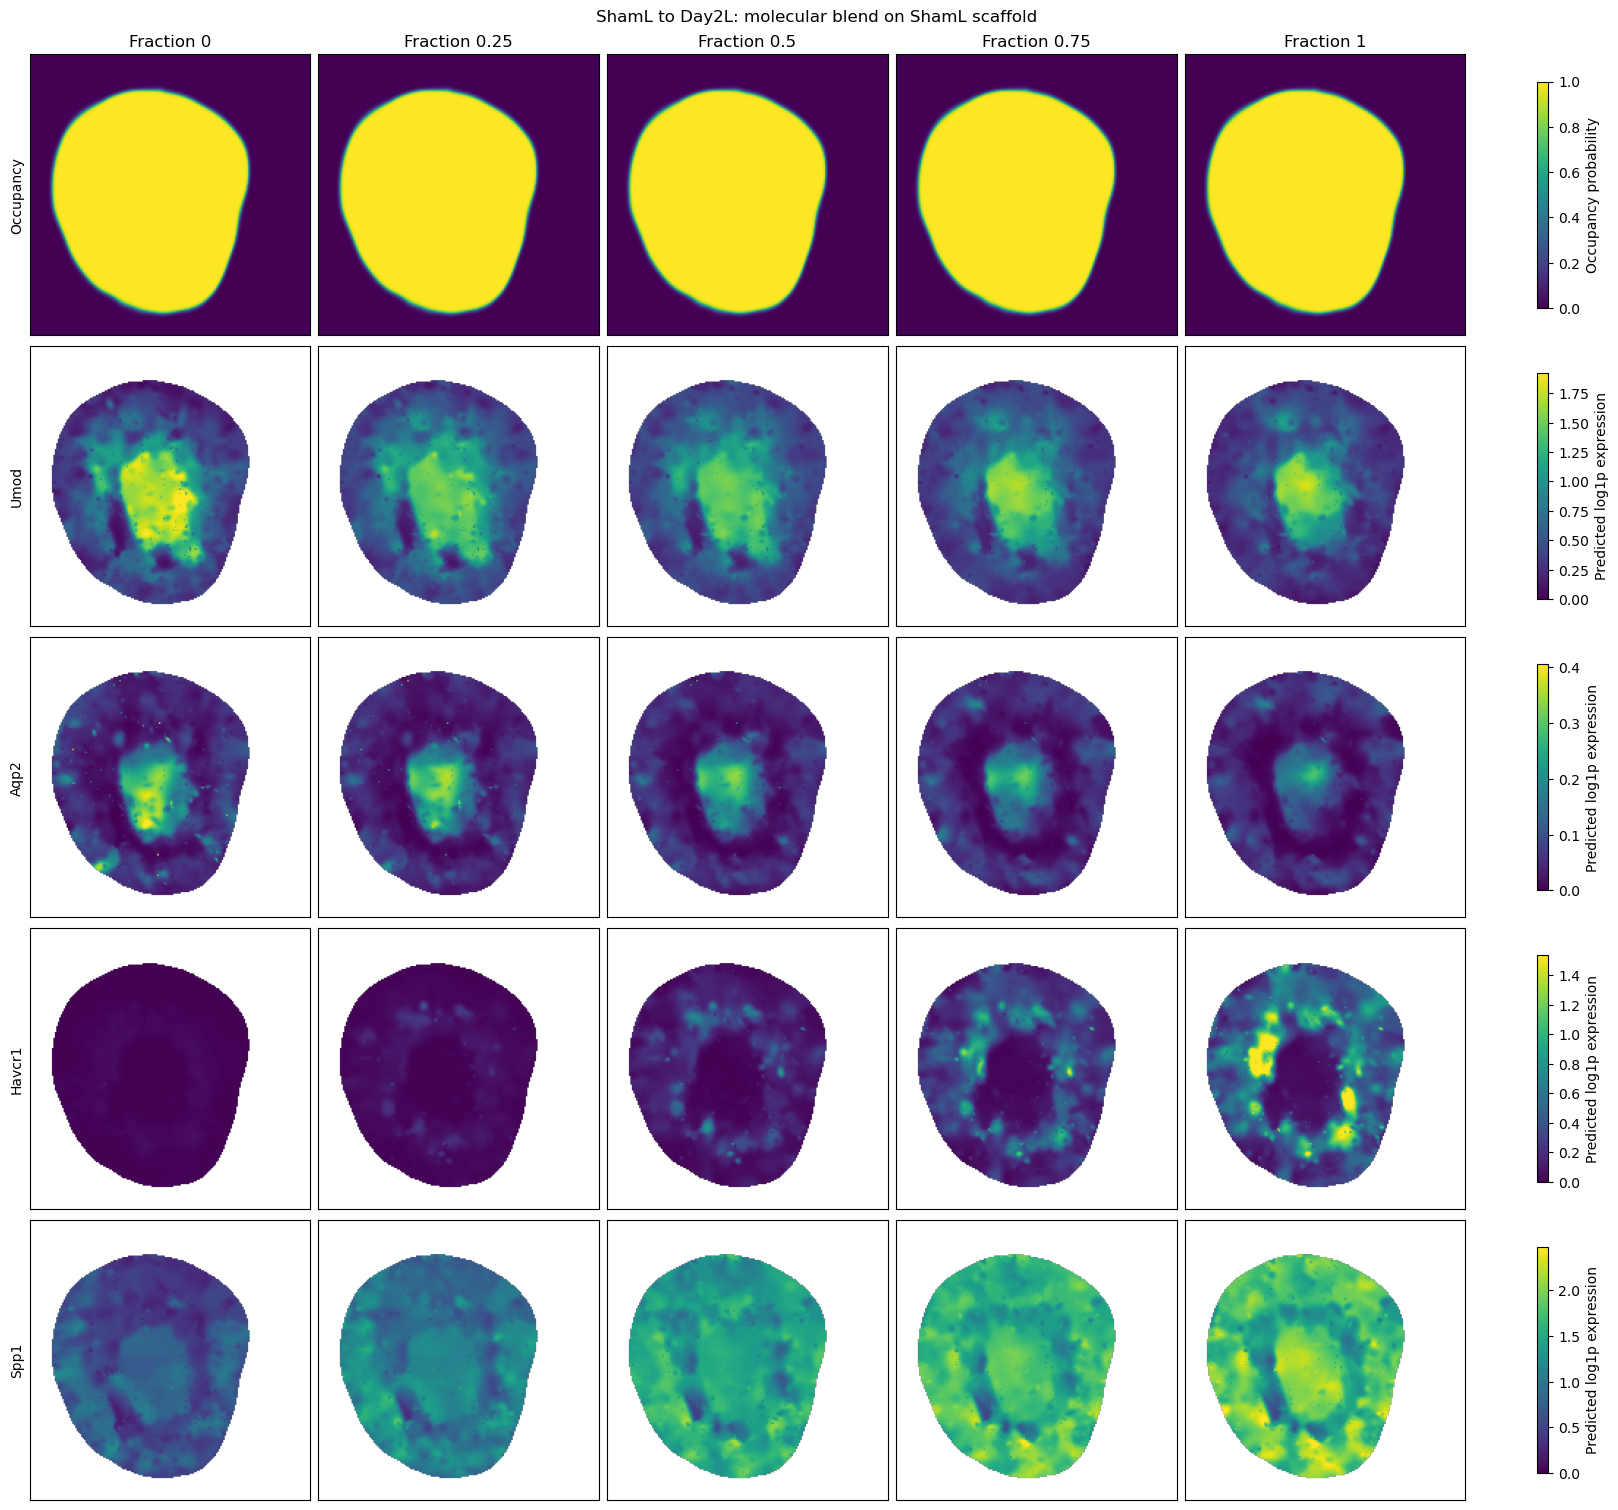

,fraction,gene,occupied_mean,occupied_max
0,0,Umod,0.6948,2.223
1,0.25,Umod,0.7212,1.767
2,0.5,Umod,0.6793,1.579
3,0.75,Umod,0.6108,1.718
4,1,Umod,0.5247,1.816
5,0,Aqp2,0.08088,0.5172
6,0.25,Aqp2,0.06835,0.3803
7,0.5,Aqp2,0.06399,0.3391
8,0.75,Aqp2,0.06211,0.3157
9,1,Aqp2,0.05371,0.2913


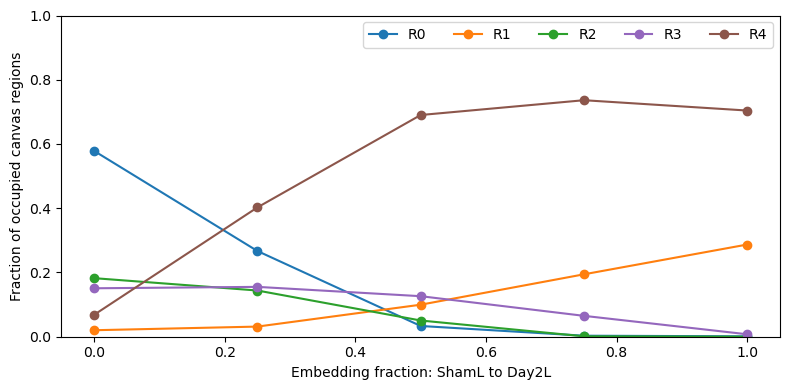

Fixed-scaffold outputs: /data/spatsplat/data/processed/kidney_iri_occupancy/9eca165c456f/scaffold_blends/6dfdf84e5161


In [13]:
if scaffold_results:
    markers = [g for g in MARKERS if g in genes]
    fig, axes = plt.subplots(1+len(markers), len(scaffold_results),
        figsize=(3*len(scaffold_results)+1, 3*(1+len(markers))), squeeze=False, layout='constrained')
    marker_rows = []
    for col, rendered in enumerate(scaffold_results):
        image = axes[0, col].imshow(rendered['probability'].reshape(size, size),
            origin='lower', extent=extent, vmin=0, vmax=1, cmap='viridis')
        axes[0, col].set_title(f'Fraction {rendered["fraction"]:.4g}')
    fig.colorbar(image, ax=list(axes[0]), label='Occupancy probability', shrink=.8)
    axes[0, 0].set_ylabel('Occupancy')
    observed_endpoints = np.concatenate([regions[r['section'], PLOT_WIDTH_UM]['values']['Observed']
                                         for r in [scaffold_left, scaffold_right]])
    for row, gene in enumerate(markers, start=1):
        gene_index = np.flatnonzero(genes == gene)[0]
        upper = max(float(np.quantile(observed_endpoints[:, gene_index], .99)), 1e-8)
        for col, rendered in enumerate(scaffold_results):
            mask = rendered['probability'] >= OCC_CFG['threshold']
            values = rendered['expression'][:, gene_index]
            shown = np.ma.array(values.reshape(size, size), mask=~mask.reshape(size, size))
            image = axes[row, col].imshow(shown, origin='lower', extent=extent,
                cmap='viridis', vmin=0, vmax=upper)
            marker_rows.append(dict(fraction=rendered['fraction'], gene=gene,
                occupied_mean=float(values[mask].mean()) if mask.any() else np.nan,
                occupied_max=float(values[mask].max()) if mask.any() else np.nan))
        axes[row, 0].set_ylabel(gene)
        fig.colorbar(image, ax=list(axes[row]), label='Predicted log1p expression', shrink=.8)
    for ax in axes.ravel():
        ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(f'{SCAFFOLD_LEFT} to {SCAFFOLD_RIGHT}: molecular blend on {SCAFFOLD_SAMPLE} scaffold')
    fig.savefig(OCC_FIGURES/f'scaffold_{SCAFFOLD_ID}_maps.png', dpi=180, bbox_inches='tight'); plt.show()
    marker_table = pd.DataFrame(marker_rows)
    marker_table.to_csv(SCAFFOLD_OUTPUT/'marker_summary.csv', index=False)
    display(marker_table)
    fig, ax = plt.subplots(figsize=(8, 4))
    for i, color in enumerate(state_colors):
        group = scaffold_states[scaffold_states.state == f'R{i}']
        ax.plot(group.fraction, group.region_fraction, marker='o', color=color, label=f'R{i}')
    ax.set(xlabel=f'Embedding fraction: {SCAFFOLD_LEFT} to {SCAFFOLD_RIGHT}',
        ylabel='Fraction of occupied canvas regions', ylim=(0, 1))
    ax.legend(ncol=len(state_colors)); fig.tight_layout()
    fig.savefig(OCC_FIGURES/f'scaffold_{SCAFFOLD_ID}_states.png', dpi=180); plt.show()
    print('Fixed-scaffold outputs:', SCAFFOLD_OUTPUT)
